# Exp28 — Experiment B: does grammatical-gender state transfer across languages? (same DTI instrument as Exp27)

**Why this exists.** The "inversion" story (gender = universal register, word order = wall) needs *both* legs measured with the *same* instrument. Exp27 measured word order. This measures gender. **This is a NEW pre-registered study** (own results folder, own frozen rule); it does not rescue or alter the Exp27 verdict.

**Design.** 16 inanimate concepts (moon, door, wall, bag, river, tooth …) in FR / ES / HI / AR, chosen so grammatical gender splits **2–2 across the four languages** — every recipient item has a same-gender and an opposite-gender donor. 6 of the 16 concepts split *across* the Romance pair (e.g. river: FR+HI fem, ES+AR masc), so gender can be separated from language family.

Prefix ends **right before the agreeing adjective** (FR "Les lunes sont", ES "Dos lunas están", HI bare noun, AR definite noun): no gender-marked article in the prefix. Candidates = feminine vs masculine form of the *same* adjective + a fixed terminator (fixes the length bias that e.g. AR fem = masc + ة would create).
`S = logP(fem form) − logP(masc form)`; `shift_toward` = native margin lost after patching; `flip` = native gender no longer preferred. Residual patch at the last prefix token, one layer at a time, late window = layers ≥ 50% depth.

Donor kinds per recipient item:
| kind | donor | meaning |
|---|---|---|
| `opp` | other language, same concept, **opposite** gender | transfer signal |
| `same` | other language, same concept, same gender | foreign-state control |
| `ceil` | **same language**, different concept, opposite gender | in-language ceiling |
| `floor` | **same language**, different concept, same gender | in-language floor |

`DTI = metric(opp) − metric(same)`; `ceiling = metric(ceil) − metric(floor)` (both per scene, bootstrapped over scenes).

**Pre-registered rule** (frozen to `exp28_results/prereg.json` on first run):
1. Cell usable only if clean native-gender accuracy ≥ 0.75 on ≥ 8 items **and** that language's own in-language ceiling (flip) ≥ 0.30 (per-language ceiling gate — the instrument must be able to see transfer *in that language*).
2. Clean cell: ≥ 2 opposite-gender donors, ≥ 1 same-gender donor, ≥ 8 scenes.
3. **TRANSFER** iff DTI ≥ 0.15 **and** DTI on the 6 cross-family concepts ≥ 0.15 (≥ 4 scenes) **and** still ≥ 0.15 after dropping any single donor language. **WALL** iff DTI ≤ 0.05. Else AMBIGUOUS.
4. ≥ 3 usable cells required, else INSTRUMENT_INADEQUATE. ≥ 3 TRANSFER cells → **REGISTER_SUPPORTED**. ≥ 3 WALL cells → **REGISTER_REJECTED**. Otherwise INCONCLUSIVE.

The last cell compares ceiling-normalised transfer for gender against Exp27's word-order cells (descriptive only; it is not part of the rule).

**What a TRANSFER means / does not mean.** It means the late-layer state at the decision token carries a gender code that overrides another language's lexical gender, beyond what a foreign state does generically. It does not show a single 1-D register (B4 probes), and it does not show *where* the gender was computed. A WALL would mean last-token patching cannot carry gender across languages although it can within each language.

**VERIFY with a native speaker before any claim:** every gender assignment in the table (esp. HI थैला, दीपक; AR الكوب, الصحن; ES *pez*), the HI/AR adjective forms, and the ES/FR frames.

In [1]:
import os, json
# ============================ CONFIG ============================
GPU_ID       = 2
MODEL_KEY    = "gemma-2-9b"          # rerun with "gemma-2-2b" / "gemma-2-27b-it"
MODEL_PATHS  = {
    "gemma-2-2b":     "google/gemma-2-2b",
    "gemma-2-9b":     "/home/models/gemma-2-9b",
    "gemma-2-9b-it":  "/home/models/gemma-2-9b-it",
    "gemma-2-27b-it": "/home/models/gemma-2-27b-it",
}
DTYPE          = "bfloat16"
RESULTS_DIR    = "exp28_results"
EXP27_DIR      = "exp27_results"      # only read by the last (descriptive) cell
LAYER_STRIDE   = 2
LATE_FRAC      = 0.5
N_WITHIN       = 4        # same-language donors per recipient for each of floor / ceil
BATCH          = 96
N_BOOT         = 2000
SEED           = 0

# ---------------- PRE-REGISTERED DECISION RULE (NEW STUDY; frozen on first run) ----------------
PREREG = dict(
    gate_acc=0.75, gate_min_items=8,
    ceil_min=0.30,                 # per-language in-language ceiling (flip, late window)
    wall_max=0.05, transfer_min=0.15,
    min_opp_donors=2, min_same_donors=1, min_scenes=8, min_xfam_scenes=4,
    min_usable_cells=3, min_transfer_cells=3, min_wall_cells=3,
    primary_metric="flip", window_frac=LATE_FRAC,
)
os.makedirs(RESULTS_DIR, exist_ok=True)
_p = f"{RESULTS_DIR}/prereg.json"
_payload = json.dumps(PREREG, sort_keys=True, indent=1)
if os.path.exists(_p):
    if open(_p).read() != _payload:
        raise RuntimeError("PREREG differs from the frozen exp28_results/prereg.json. A changed decision rule is a different study: use a new RESULTS_DIR.")
else:
    open(_p, "w").write(_payload)
print("prereg frozen:", PREREG)

prereg frozen: {'gate_acc': 0.75, 'gate_min_items': 8, 'ceil_min': 0.3, 'wall_max': 0.05, 'transfer_min': 0.15, 'min_opp_donors': 2, 'min_same_donors': 1, 'min_scenes': 8, 'min_xfam_scenes': 4, 'min_usable_cells': 3, 'min_transfer_cells': 3, 'min_wall_cells': 3, 'primary_metric': 'flip', 'window_frac': 0.5}


In [2]:
import time, math, random, glob
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU_ID)      # must precede the first CUDA call
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RNG = np.random.default_rng(SEED)
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.11.0+cu130 | cuda: True


In [3]:
# ============================ ITEM BANK (VERIFY every gender + form with a native speaker) ============================
LANGS  = ["fr", "es", "hi", "ar"]
FAMILY = {"fr": "romance", "es": "romance", "hi": "indo-aryan", "ar": "semitic"}
SCRIPT = {"fr": "latin", "es": "latin", "hi": "deva", "ar": "arab"}
TERM   = {"fr": ".", "es": ".", "hi": " है", "ar": "."}      # fixed terminator after the adjective (marks word completion)

# adjective -> {lang: (feminine form, masculine form)}; all have distinct F/M forms; FR/ES plural, HI/AR singular
ADJ = {
 "hidden":    {"fr": ("cachées","cachés"),    "es": ("escondidas","escondidos"), "hi": ("छिपी","छिपा"),   "ar": ("مخفية","مخفي")},
 "open":      {"fr": ("ouvertes","ouverts"),  "es": ("abiertas","abiertos"),     "hi": ("खुली","खुला"),   "ar": ("مفتوحة","مفتوح")},
 "cold":      {"fr": ("froides","froids"),    "es": ("frías","fríos"),           "hi": ("ठंडी","ठंडा"),   "ar": ("باردة","بارد")},
 "forgotten": {"fr": ("oubliées","oubliés"),  "es": ("olvidadas","olvidados"),   "hi": ("भूली","भूला"),   "ar": ("منسية","منسي")},
 "broken":    {"fr": ("cassées","cassés"),    "es": ("rotas","rotos"),           "hi": ("टूटी","टूटा"),   "ar": ("مكسورة","مكسور")},
 "lost":      {"fr": ("perdues","perdus"),    "es": ("perdidas","perdidos"),     "hi": ("खोई","खोया"),   "ar": ("ضائعة","ضائع")},
 "black":     {"fr": ("noires","noirs"),      "es": ("negras","negros"),         "hi": ("काली","काला"),   "ar": ("سوداء","أسود")},
}
# concept, adjective, {lang: (prefix ending right before the adjective, grammatical gender)}   -- every row is a 2-2 gender split
CONCEPTS = [
 ("moon",     "hidden",    {"fr": ("Les lunes sont","F"),      "es": ("Dos lunas están","F"),      "hi": ("चाँद","M"),   "ar": ("القمر","M")}),
 ("door",     "open",      {"fr": ("Les portes sont","F"),     "es": ("Dos puertas están","F"),    "hi": ("दरवाज़ा","M"), "ar": ("الباب","M")}),
 ("house",    "cold",      {"fr": ("Les maisons sont","F"),    "es": ("Dos casas están","F"),      "hi": ("घर","M"),     "ar": ("البيت","M")}),
 ("mountain", "forgotten", {"fr": ("Les montagnes sont","F"),  "es": ("Dos montañas están","F"),   "hi": ("पहाड़","M"),   "ar": ("الجبل","M")}),
 ("river",    "cold",      {"fr": ("Les rivières sont","F"),   "es": ("Dos ríos están","M"),       "hi": ("नदी","F"),    "ar": ("النهر","M")}),
 ("wall",     "broken",    {"fr": ("Les murs sont","M"),       "es": ("Dos paredes están","F"),    "hi": ("दीवार","F"),   "ar": ("الجدار","M")}),
 ("cup",      "broken",    {"fr": ("Les tasses sont","F"),     "es": ("Dos tazas están","F"),      "hi": ("कप","M"),     "ar": ("الكوب","M")}),
 ("bag",      "lost",      {"fr": ("Les sacs sont","M"),       "es": ("Dos bolsas están","F"),     "hi": ("थैला","M"),    "ar": ("الحقيبة","F")}),
 ("fire",     "hidden",    {"fr": ("Les feux sont","M"),       "es": ("Dos fuegos están","M"),     "hi": ("आग","F"),     "ar": ("النار","F")}),
 ("wind",     "cold",      {"fr": ("Les vents sont","M"),      "es": ("Dos vientos están","M"),    "hi": ("हवा","F"),    "ar": ("الريح","F")}),
 ("stone",    "black",     {"fr": ("Les pierres sont","F"),    "es": ("Dos piedras están","F"),    "hi": ("पत्थर","M"),   "ar": ("الحجر","M")}),
 ("fish",     "black",     {"fr": ("Les poissons sont","M"),   "es": ("Dos peces están","M"),      "hi": ("मछली","F"),   "ar": ("السمكة","F")}),
 ("lamp",     "broken",    {"fr": ("Les lampes sont","F"),     "es": ("Dos lámparas están","F"),   "hi": ("दीपक","M"),   "ar": ("المصباح","M")}),
 ("plate",    "black",     {"fr": ("Les assiettes sont","F"),  "es": ("Dos platos están","M"),     "hi": ("थाली","F"),   "ar": ("الصحن","M")}),
 ("ring",     "lost",      {"fr": ("Les bagues sont","F"),     "es": ("Dos anillos están","M"),    "hi": ("अंगूठी","F"),  "ar": ("الخاتم","M")}),
 ("tooth",    "broken",    {"fr": ("Les dents sont","F"),      "es": ("Dos dientes están","M"),    "hi": ("दाँत","M"),   "ar": ("السن","F")}),
]
XFAM = {i for i, (k, a, d) in enumerate(CONCEPTS) if d["fr"][1] != d["es"][1]}      # Romance pair disagrees -> gender is not collinear with family
for k, a, d in CONCEPTS:
    gs = [d[l][1] for l in LANGS]
    assert gs.count("F") == 2 and gs.count("M") == 2, k           # 2-2 split guarantees opp AND same donors for every recipient

UNITS = []
for s, (concept, adj, d) in enumerate(CONCEPTS):
    for l in LANGS:
        prefix, g = d[l]
        fem, masc = ADJ[adj][l]
        UNITS.append(dict(uid=len(UNITS), constr="gender", lang=l, scene=s, concept=concept, prefix=prefix, hf=fem + TERM[l], hl=masc + TERM[l],
                          native="first" if g == "F" else "last", sep=" ", gender=g, sign=1 if g == "F" else -1, xfam=(s in XFAM)))
print(len(UNITS), "units;", len(XFAM), "cross-family concepts:", sorted(CONCEPTS[i][0] for i in XFAM))
for u in UNITS[:4]: print(u["lang"], "|", u["prefix"], "| F:", u["hf"], "| M:", u["hl"], "| native", u["gender"])

64 units; 6 cross-family concepts: ['bag', 'plate', 'ring', 'river', 'tooth', 'wall']
fr | Les lunes sont | F: cachées. | M: cachés. | native F
es | Dos lunas están | F: escondidas. | M: escondidos. | native F
hi | चाँद | F: छिपी है | M: छिपा है | native M
ar | القمر | F: مخفية. | M: مخفي. | native M


In [4]:
# ============================ MODEL + CORE MACHINERY ============================
from transformers import AutoTokenizer, AutoModelForCausalLM
if "model" not in globals():
    _path = MODEL_PATHS[MODEL_KEY]
    tok = AutoTokenizer.from_pretrained(_path)
    _kw = dict(torch_dtype=getattr(torch, DTYPE), device_map={"": 0})
    if "gemma" in MODEL_KEY: _kw["attn_implementation"] = "eager"
    model = AutoModelForCausalLM.from_pretrained(_path, **_kw)
    model.eval()

def get_layers(m):
    for path in ("model.layers", "transformer.h", "gpt_neox.layers"):
        obj = m
        try:
            for a in path.split("."): obj = getattr(obj, a)
            return list(obj)
        except AttributeError:
            continue
    raise RuntimeError("cannot find decoder layers")

LAYERS = get_layers(model); NL = len(LAYERS)
DEVM = next(model.parameters()).device
PAD_ID = tok.pad_token_id if tok.pad_token_id is not None else (tok.eos_token_id or 0)
LAYER_LIST = sorted(set(list(range(0, NL, LAYER_STRIDE)) + [NL-1]))
LATE0 = int(NL * LATE_FRAC)
print(f"{MODEL_KEY}: {NL} layers | patching layers {LAYER_LIST} | late window = layers >= {LATE0}")

def collate(id_lists):
    T = max(len(x) for x in id_lists)
    ids  = torch.full((len(id_lists), T), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(id_lists), T), dtype=torch.long)
    for i, x in enumerate(id_lists):
        ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1
    pos = torch.tensor([len(x) - 1 for x in id_lists], dtype=torch.long)
    return ids.to(DEVM), mask.to(DEVM), pos.to(DEVM)

def make_patch_hook(pos, vecs):
    def hook(mod, inp, out):
        h = out[0] if isinstance(out, tuple) else out
        h2 = h.clone()
        h2[torch.arange(h2.shape[0], device=h2.device), pos.to(h2.device)] = vecs.to(device=h2.device, dtype=h2.dtype)
        return (h2,) + tuple(out[1:]) if isinstance(out, tuple) else h2
    return hook

def encode_unit(u):
    ids_p = tok(u["prefix"])["input_ids"]
    rows, ok = [], True
    for key in ("hf", "hl"):
        ids = tok(u["prefix"] + u["sep"] + u[key])["input_ids"]
        if len(ids) <= len(ids_p) or ids[:len(ids_p)] != ids_p: ok = False
        rows.append(dict(ids=ids, p=len(ids_p) - 1, n=len(ids) - len(ids_p)))
    u["ids_p"], u["rows"], u["ok"] = ids_p, rows, ok
for u in UNITS: encode_unit(u)

@torch.no_grad()
def score_rows(rows, layer=None, vecs=None):
    out_lp = []
    for i in range(0, len(rows), BATCH):
        chunk = rows[i:i+BATCH]
        ids, mask, _ = collate([r["ids"] for r in chunk])
        pos = torch.tensor([r["p"] for r in chunk], dtype=torch.long, device=DEVM)
        hk = LAYERS[layer].register_forward_hook(make_patch_hook(pos, vecs[i:i+BATCH])) if layer is not None else None
        try:
            lg = model(input_ids=ids, attention_mask=mask, use_cache=False).logits
        finally:
            if hk is not None: hk.remove()
        for b, r in enumerate(chunk):
            l = torch.log_softmax(lg[b, r["p"]: r["p"] + r["n"]].float(), -1)
            tgt = torch.tensor(r["ids"][r["p"] + 1: r["p"] + 1 + r["n"]], device=l.device)
            out_lp.append(l.gather(1, tgt[:, None]).sum().item())
    return np.array(out_lp)

@torch.no_grad()
def capture_states(units):
    res = []
    for i in range(0, len(units), BATCH):
        chunk = units[i:i+BATCH]
        ids, mask, pos = collate([u["ids_p"] for u in chunk])
        store, hs = {}, []
        for li, layer in enumerate(LAYERS):
            def mk(li):
                def hook(m, inp, out):
                    h = out[0] if isinstance(out, tuple) else out
                    store[li] = h[torch.arange(h.shape[0], device=h.device), pos.to(h.device)].float().cpu()
                return hook
            hs.append(layer.register_forward_hook(mk(li)))
        try:
            model(input_ids=ids, attention_mask=mask, use_cache=False)
        finally:
            for h in hs: h.remove()
        res.append(torch.stack([store[li] for li in range(NL)], 1))
    return torch.cat(res)

@torch.no_grad()
def logp_at_decision(prefix_ids, layer=None, vecs=None):
    ids, mask, pos = collate(prefix_ids)
    hk = LAYERS[layer].register_forward_hook(make_patch_hook(pos, vecs)) if layer is not None else None
    try:
        lg = model(input_ids=ids, attention_mask=mask, use_cache=False).logits
    finally:
        if hk is not None: hk.remove()
    return torch.log_softmax(lg[torch.arange(len(prefix_ids)), pos].float(), -1).cpu()

print(f"tokenisation check: {sum(1 for u in UNITS if not u['ok'])}/{len(UNITS)} units fail the prefix-consistency test (dropped automatically)")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 464/464 [00:01<00:00, 289.14it/s]


gemma-2-9b: 42 layers | patching layers [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 41] | late window = layers >= 21
tokenisation check: 0/64 units fail the prefix-consistency test (dropped automatically)


In [5]:
# ============================ SELF-TESTS ============================
STATES = capture_states(UNITS)
print("captured states", tuple(STATES.shape))
def _units(lang, k=12): return [u for u in UNITS if u["lang"] == lang and u["ok"]][:k]

# (1) self-patch: patching a prompt with its OWN state must leave the score unchanged (any deviation = bf16 noise floor)
us = _units("fr"); rows = [r for u in us for r in u["rows"]]
S0 = score_rows(rows); NOISE = 0.0
for L in (LAYER_LIST[len(LAYER_LIST)//2], LAYER_LIST[-1]):
    vecs = torch.stack([STATES[u["uid"], L] for u in us for _ in (0, 1)])
    NOISE = max(NOISE, float(np.abs(score_rows(rows, L, vecs) - S0).max()))
print(f"[1] self-patch max |delta logP| = {NOISE:.4f}  (= numerical noise floor of this model/dtype)")
assert NOISE < 0.5, "hook is broken: self-patch changes the score"

# (2) overwrite: patching the LAST layer at the decision token must reproduce the donor's next-token distribution there.
#     Compared on tokens with donor prob > 3e-4 (tail-token log-probs are pure bf16 noise) + argmax agreement.
rec = _units("fr", 8); don = [next(x for x in UNITS if x["lang"] == "ar" and x["scene"] == u["scene"]) for u in rec]
A = logp_at_decision([d["ids_p"] for d in don]).numpy()
B = logp_at_decision([u["ids_p"] for u in rec], NL - 1, torch.stack([STATES[d["uid"], NL - 1] for d in don])).numpy()
m = A > -8.0
dmax, agree = float(np.abs(A - B)[m].max()), float((A.argmax(1) == B.argmax(1)).mean())
print(f"[2] last-layer overwrite: max |delta log-prob| on probable tokens = {dmax:.4f}; argmax agreement = {agree:.2f}")
assert dmax < 0.5 and agree >= 0.9, "patch is not landing on the decision position"

# (3) a mid-depth patch from another language must be able to change the score (informational)
Lmid = LAYER_LIST[len(LAYER_LIST)//2]
Sx = score_rows([r for u in rec for r in u["rows"]], Lmid, torch.stack([STATES[d["uid"], Lmid] for d in don for _ in (0, 1)]))
print(f"[3] mean |S change| when patching an AR state into FR at layer {Lmid}: {np.abs(Sx - score_rows([r for u in rec for r in u['rows']])).mean():.3f} nats (informational)")
print(f"SELF-TESTS PASSED | interpret no shift below ~{2*NOISE:.2f} nats")

captured states (64, 42, 3584)
[1] self-patch max |delta logP| = 0.2191  (= numerical noise floor of this model/dtype)
[2] last-layer overwrite: max |delta log-prob| on probable tokens = 0.2256; argmax agreement = 1.00
[3] mean |S change| when patching an AR state into FR at layer 22: 9.376 nats (informational)
SELF-TESTS PASSED | interpret no shift below ~0.44 nats


In [6]:
# ============================ PREFLIGHT GATE: does each language know its concepts' gender at the decision token? ============================
okU = [u for u in UNITS if u["ok"]]
S_all = score_rows([r for u in okU for r in u["rows"]])
for k, u in enumerate(okU):
    u["S0"] = float(S_all[2*k] - S_all[2*k + 1])          # logP(fem) - logP(masc)
    u["margin"] = u["S0"] * u["sign"]
    u["clean_ok"] = u["margin"] > 0
for u in UNITS:
    if not u["ok"]: u["S0"], u["margin"], u["clean_ok"] = np.nan, np.nan, False

gate_rows, PASS = [], {}
for l in LANGS:
    us = [u for u in UNITS if u["lang"] == l]; okc = [u for u in us if u["ok"]]
    acc = float(np.mean([u["clean_ok"] for u in okc])) if okc else float("nan")
    accF = float(np.mean([u["clean_ok"] for u in okc if u["gender"] == "F"])) if any(u["gender"] == "F" for u in okc) else np.nan
    accM = float(np.mean([u["clean_ok"] for u in okc if u["gender"] == "M"])) if any(u["gender"] == "M" for u in okc) else np.nan
    PASS[l] = (len(okc) >= PREREG["gate_min_items"]) and (acc >= PREREG["gate_acc"])
    gate_rows.append(dict(lang=l, n_tok_ok=len(okc), clean_acc=round(acc, 2), acc_F=round(accF, 2), acc_M=round(accM, 2),
                          mean_margin=round(float(np.nanmean([u["margin"] for u in okc])), 2) if okc else np.nan,
                          mean_S_fem_items=round(float(np.nanmean([u["S0"] for u in okc if u["gender"] == "F"])), 2),
                          mean_S_masc_items=round(float(np.nanmean([u["S0"] for u in okc if u["gender"] == "M"])), 2), PASS=PASS[l]))
GATE = pd.DataFrame(gate_rows); print(GATE.to_string(index=False))
GATE.to_csv(f"{RESULTS_DIR}/{MODEL_KEY}_preflight_gate.csv", index=False)
print("\nIf acc_F and acc_M differ a lot, the fem/masc candidates have a length/morphology bias in that language (inspect mean_S_*).")
print("usable languages:", [l for l in LANGS if PASS[l]])

lang  n_tok_ok  clean_acc  acc_F  acc_M  mean_margin  mean_S_fem_items  mean_S_masc_items  PASS
  fr        16       1.00   1.00   1.00         5.41              5.21              -5.86  True
  es        16       1.00   1.00   1.00         6.00              5.93              -6.09  True
  hi        16       0.62   0.57   0.67         1.19              0.99              -1.34 False
  ar        16       0.75   0.80   0.73         2.35              2.00              -2.51  True

If acc_F and acc_M differ a lot, the fem/masc candidates have a length/morphology bias in that language (inspect mean_S_*).
usable languages: ['fr', 'es', 'ar']


In [7]:
# ============================ CORE PATCHING RUN ============================
def donor_pairs():
    by = {(u["lang"], u["scene"]): u for u in UNITS}
    nsc = len(CONCEPTS)
    good = lambda u: u["ok"] and u["clean_ok"]
    pairs = []
    for r in UNITS:
        if not PASS.get(r["lang"], False) or not good(r): continue
        for dl in LANGS:                                            # cross-language, SAME concept
            if dl == r["lang"] or not PASS.get(dl, False): continue
            d = by[(dl, r["scene"])]
            if not good(d): continue
            pairs.append((r["uid"], d["uid"], "same" if d["native"] == r["native"] else "opp", dl))
        nf = nc = 0                                                  # same language, DIFFERENT concept: floor (same gender) / ceil (opposite gender)
        for k in range(1, nsc):
            d = by[(r["lang"], (r["scene"] + k) % nsc)]
            if not good(d): continue
            if d["native"] == r["native"] and nf < N_WITHIN: pairs.append((r["uid"], d["uid"], "floor", r["lang"])); nf += 1
            elif d["native"] != r["native"] and nc < N_WITHIN: pairs.append((r["uid"], d["uid"], "ceil", r["lang"])); nc += 1
    return pairs

def run_patching():
    path = f"{RESULTS_DIR}/{MODEL_KEY}_gender.csv"
    if os.path.exists(path):
        print("cached:", path); return pd.read_csv(path)
    pairs = donor_pairs()
    print(f"gender: {len(pairs)} (recipient, donor) pairs x {len(LAYER_LIST)} layers"); t0 = time.time()
    recs = []
    for L in LAYER_LIST:
        rows, vecs = [], []
        for (ri, di, kind, dl) in pairs:
            rows += UNITS[ri]["rows"]; vecs += [STATES[di, L], STATES[di, L]]
        lp = score_rows(rows, L, torch.stack(vecs))
        for k, (ri, di, kind, dl) in enumerate(pairs):
            r = UNITS[ri]
            recs.append(dict(recip=r["lang"], scene=r["scene"], xfam=r["xfam"], donor=dl, kind=kind, layer=L,
                             S_clean=r["S0"], S_patched=float(lp[2*k] - lp[2*k + 1]), sign=r["sign"]))
        print(f"  layer {L:3d} done ({time.time()-t0:.0f}s)", end="\r")
    df = pd.DataFrame(recs)
    df["shift_toward"] = -df["sign"] * (df["S_patched"] - df["S_clean"])     # native margin lost (nats)
    df["flip"] = ((df["S_patched"] * df["sign"]) < 0).astype(float)           # native gender no longer preferred
    df.to_csv(path, index=False)
    return df

DF = run_patching(); print(DF.shape); print(DF.groupby("kind").size().to_dict())

gender: 428 (recipient, donor) pairs x 22 layers
(9416, 11)1 done (11s)
{'ceil': 3872, 'floor': 3784, 'opp': 1144, 'same': 616}


In [8]:
# ============================ ANALYSIS ============================
W = DF[DF.layer >= LATE0].groupby(["recip", "scene", "xfam", "kind", "donor"], as_index=False)[["shift_toward", "flip"]].mean()

def scene_vals(recip, a, b, metric, donors=None, scenes=None):
    w = W[W.recip == recip]
    if scenes is not None: w = w[w.scene.isin(scenes)]
    if donors is not None: w = w[(w.kind.isin(["floor", "ceil"])) | w.donor.isin(donors)]
    pa = w[w.kind == a].groupby("scene")[metric].mean(); pb = w[w.kind == b].groupby("scene")[metric].mean()
    return (pa - pb).dropna()

def boot(x, nb=N_BOOT):
    x = np.asarray(x, float)
    if len(x) == 0: return (np.nan, np.nan, np.nan)
    bm = x[RNG.integers(0, len(x), (nb, len(x)))].mean(1)
    return float(x.mean()), float(np.percentile(bm, 2.5)), float(np.percentile(bm, 97.5))

def cell_report(r):
    wr = W[W.recip == r]
    opp, same = sorted(wr[wr.kind == "opp"].donor.unique()), sorted(wr[wr.kind == "same"].donor.unique())
    out = dict(recip=r, n_opp=len(opp), n_same=len(same))
    x = scene_vals(r, "opp", "same", "flip"); out["n_scenes"] = len(x)
    out["dti_flip"], out["lo"], out["hi"] = boot(x.values)
    out["dti_shift"], out["shift_lo"], out["shift_hi"] = boot(scene_vals(r, "opp", "same", "shift_toward").values)
    xf = scene_vals(r, "opp", "same", "flip", scenes=XFAM); out["n_xfam"] = len(xf)
    out["dti_xfam"], out["xfam_lo"], out["xfam_hi"] = boot(xf.values)
    out["dti_aligned"] = float(scene_vals(r, "opp", "same", "flip", scenes=set(range(len(CONCEPTS))) - XFAM).mean())
    cv = scene_vals(r, "ceil", "floor", "flip"); out["n_ceil_scenes"] = len(cv)
    out["ceil_flip"], out["ceil_lo"], out["ceil_hi"] = boot(cv.values)
    out["ceil_shift"] = float(scene_vals(r, "ceil", "floor", "shift_toward").mean())
    for k in ("opp", "same", "floor", "ceil"):
        v = wr[wr.kind == k]; out[f"{k}_flip"] = float(v.flip.mean()) if len(v) else np.nan
    loo = {d: scene_vals(r, "opp", "same", "flip", donors=[o for o in opp if o != d]) for d in opp}
    loo = {d: float(v.mean()) for d, v in loo.items() if len(v)} if len(opp) > 1 else {}
    out["loo_min"] = min(loo.values()) if loo else np.nan; out["loo_drop"] = min(loo, key=loo.get) if loo else ""
    oth = [d for d in set(opp) | set(same) if FAMILY[d] != FAMILY[r]]
    xo = scene_vals(r, "opp", "same", "flip", donors=oth)
    out["dti_other_family_donors"] = float(xo.mean()) if len(xo) else np.nan; out["n_other_fam_scenes"] = len(xo)
    out["frac_of_ceiling"] = out["dti_flip"] / out["ceil_flip"] if out["ceil_flip"] and out["ceil_flip"] > 0 else np.nan
    return out

def classify(r):
    P = PREREG
    if not (r["ceil_flip"] >= P["ceil_min"]): return "NO_CEILING"
    if not (r["n_opp"] >= P["min_opp_donors"] and r["n_same"] >= P["min_same_donors"] and r["n_scenes"] >= P["min_scenes"]): return "UNUSABLE"
    if r["dti_flip"] >= P["transfer_min"] and r["n_xfam"] >= P["min_xfam_scenes"] and r["dti_xfam"] >= P["transfer_min"] and r["loo_min"] >= P["transfer_min"]: return "TRANSFER"
    if r["dti_flip"] <= P["wall_max"]: return "WALL"
    return "AMBIGUOUS"

REP = pd.DataFrame([cell_report(r) for r in sorted(W.recip.unique())]); REP["class"] = REP.apply(classify, axis=1)
REP.to_csv(f"{RESULTS_DIR}/{MODEL_KEY}_cell_report.csv", index=False)
print("=== in-language ceiling (same language, different concept, opposite vs same gender; flip, late window) ===")
print(REP[["recip", "n_ceil_scenes", "ceil_flip", "ceil_lo", "ceil_hi", "ceil_shift", "floor_flip"]].round(3).to_string(index=False))
print("\n=== cross-language gender DTI, late window (flip primary) ===")
cols = ["recip", "n_opp", "n_same", "n_scenes", "dti_flip", "lo", "hi", "opp_flip", "same_flip", "dti_xfam", "n_xfam", "dti_aligned", "loo_min", "loo_drop", "dti_other_family_donors", "dti_shift", "frac_of_ceiling", "class"]
print(REP[cols].round(3).to_string(index=False))

=== in-language ceiling (same language, different concept, opposite vs same gender; flip, late window) ===
recip  n_ceil_scenes  ceil_flip  ceil_lo  ceil_hi  ceil_shift  floor_flip
   ar             12      0.373    0.265    0.504       2.927       0.003
   es             16      0.447    0.288    0.602       6.221       0.001
   fr             16      0.457    0.278    0.646       6.277       0.000

=== cross-language gender DTI, late window (flip primary) ===
recip  n_opp  n_same  n_scenes  dti_flip    lo    hi  opp_flip  same_flip  dti_xfam  n_xfam  dti_aligned  loo_min loo_drop  dti_other_family_donors  dti_shift  frac_of_ceiling     class
   ar      2       2         4     0.205 0.068 0.273     0.250      0.000     0.205       4          NaN      NaN                             0.205      1.384            0.548  UNUSABLE
   es      2       2        11     0.215 0.041 0.430     0.455      0.189     0.212       3        0.216      NaN                               NaN      4.567    

In [9]:
# ============================ DONOR MATRIX (late window, native-gender margin lost, nats) ============================
M = W[W.kind.isin(["opp", "same"])].groupby(["recip", "kind", "donor"])["shift_toward"].mean().unstack("donor")
print("rows: recipient x kind; cols: donor language. 'opp' >> 'same' in every column = transfer; one hot column = single-donor artifact.")
print(M.round(2).to_string())
print("\nin-language: ceil vs floor (nats)"); print(W[W.kind.isin(["ceil", "floor"])].groupby(["recip", "kind"])["shift_toward"].mean().unstack("kind").round(2).to_string())

rows: recipient x kind; cols: donor language. 'opp' >> 'same' in every column = transfer; one hot column = single-donor artifact.
donor         ar    es    fr
recip kind                  
ar    opp    NaN  1.97  2.70
      same   NaN  0.73  0.68
es    opp   6.71   NaN  7.11
      same  5.71   NaN  0.87
fr    opp   2.51  4.80   NaN
      same -0.17  0.65   NaN

in-language: ceil vs floor (nats)
kind   ceil  floor
recip             
ar     2.74  -0.19
es     6.38   0.16
fr     6.20  -0.07


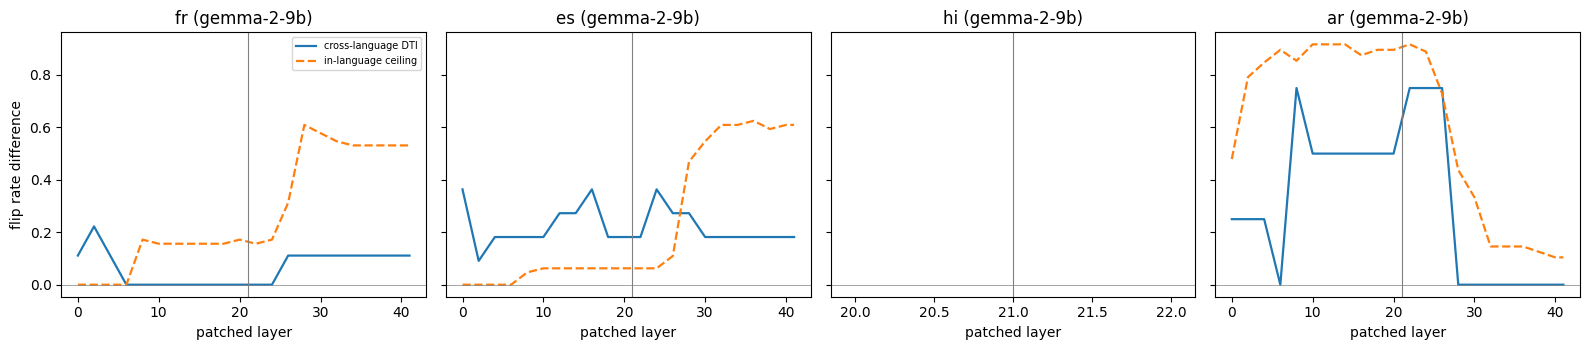

In [10]:
# ============================ PER-LAYER CURVES (exploratory) ============================
def curve(recip, a, b, metric="flip"):
    d = DF[DF.recip == recip]
    g = d.groupby(["scene", "kind", "layer"])[metric].mean().unstack("kind")
    if a not in g.columns or b not in g.columns: return pd.Series(dtype=float)
    return (g[a] - g[b]).groupby("layer").mean()
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, r in zip(axes, LANGS):
    for (a, b, lab, ls) in (("opp", "same", "cross-language DTI", "-"), ("ceil", "floor", "in-language ceiling", "--")):
        s = curve(r, a, b)
        if len(s): ax.plot(s.index, s.values, ls, label=lab, lw=1.6)
    ax.axvline(LATE0, color="grey", lw=0.8); ax.axhline(0, color="grey", lw=0.5); ax.set_title(f"{r} ({MODEL_KEY})"); ax.set_xlabel("patched layer")
axes[0].set_ylabel("flip rate difference"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/{MODEL_KEY}_gender_layer_curves.png", dpi=140); plt.show()

In [11]:
# ============================ VERDICT (mechanical application of the frozen rule) ============================
P = PREREG
usable = REP[REP["class"].isin(["TRANSFER", "WALL", "AMBIGUOUS"])]
n_t, n_w, n_a = [int((usable["class"] == k).sum()) for k in ("TRANSFER", "WALL", "AMBIGUOUS")]
if len(usable) < P["min_usable_cells"]:
    verdict = f"INSTRUMENT_INADEQUATE: only {len(usable)} usable recipient languages (need >= {P['min_usable_cells']}); classes: {REP.set_index('recip')['class'].to_dict()}"
elif n_t >= P["min_transfer_cells"]:
    verdict = f"REGISTER_SUPPORTED: {n_t}/{len(usable)} usable languages show cross-language gender transfer that survives the cross-family and leave-one-donor-out checks."
elif n_w >= P["min_wall_cells"]:
    verdict = f"REGISTER_REJECTED: {n_w}/{len(usable)} usable languages show no cross-language gender transfer although the in-language ceiling passes."
else:
    verdict = f"INCONCLUSIVE: usable={len(usable)} (TRANSFER {n_t}, WALL {n_w}, AMBIGUOUS {n_a})."
print("=" * 100); print(MODEL_KEY, "->", verdict); print("=" * 100)
print(REP[["recip", "class", "dti_flip", "lo", "hi", "ceil_flip", "frac_of_ceiling"]].round(3).to_string(index=False))
json.dump(dict(model=MODEL_KEY, verdict=verdict, prereg=PREREG, n_layers=NL, late0=LATE0, noise_floor_nats=NOISE,
               cells=REP[["recip", "class", "dti_flip", "lo", "hi", "ceil_flip", "frac_of_ceiling", "dti_xfam", "loo_min"]].round(4).to_dict("records")),
          open(f"{RESULTS_DIR}/verdict_{MODEL_KEY}.json", "w"), indent=1, default=float)

gemma-2-9b -> INSTRUMENT_INADEQUATE: only 2 usable recipient languages (need >= 3); classes: {'ar': 'UNUSABLE', 'es': 'AMBIGUOUS', 'fr': 'AMBIGUOUS'}
recip     class  dti_flip    lo    hi  ceil_flip  frac_of_ceiling
   ar  UNUSABLE     0.205 0.068 0.273      0.373            0.548
   es AMBIGUOUS     0.215 0.041 0.430      0.447            0.480
   fr AMBIGUOUS     0.091 0.000 0.273      0.457            0.199


In [12]:
# ============================ DESCRIPTIVE: gender vs word order on the SAME instrument (not part of the frozen rule) ============================
# Normalised transfer = cross-language DTI / in-language ceiling of the same language (gender) or of German frames (word order, Exp27).
rows = []
for _, r in REP.iterrows():
    rows.append(dict(task="gender", cell=r.recip, dti_flip=r.dti_flip, ceiling=r.ceil_flip,
                     normalised=r.frac_of_ceiling, lo_norm=(r.lo / r.ceil_flip if r.ceil_flip > 0 else np.nan), hi_norm=(r.hi / r.ceil_flip if r.ceil_flip > 0 else np.nan), cls=r["class"]))
f27, v27 = f"{EXP27_DIR}/{MODEL_KEY}_cell_report.csv", f"{EXP27_DIR}/verdict_{MODEL_KEY}.json"
_c27 = (json.load(open(v27)).get("ceiling") if os.path.exists(v27) else None)
if os.path.exists(f27) and _c27:
    ceil27 = _c27["flip"]
    for _, r in pd.read_csv(f27).iterrows():
        rows.append(dict(task="word order: " + r.constr, cell=r.recip, dti_flip=r.dti_flip, ceiling=ceil27,
                         normalised=r.dti_flip / ceil27, lo_norm=r.lo / ceil27, hi_norm=r.hi / ceil27, cls=r["class"]))
else:
    print("Exp27 results (with a passing German ceiling) not found at", EXP27_DIR, "- showing gender only")
CMP = pd.DataFrame(rows); print(CMP.round(3).to_string(index=False))
CMP.to_csv(f"{RESULTS_DIR}/{MODEL_KEY}_gender_vs_wordorder.csv", index=False)
print("\nmean normalised transfer by task (usable/clean cells only):")
print(CMP[CMP.cls.isin(["TRANSFER", "WALL", "AMBIGUOUS"])].groupby("task")["normalised"].agg(["mean", "min", "max", "count"]).round(3).to_string())
print("\nNOTE: ceilings are different stimuli (gender: other concept in same language; word order: German frame swap), so ratios are indicative, not a calibrated head-to-head.")

              task cell  dti_flip  ceiling  normalised  lo_norm  hi_norm       cls
            gender   ar     0.205    0.373       0.548    0.183    0.731  UNUSABLE
            gender   es     0.215    0.447       0.480    0.092    0.961 AMBIGUOUS
            gender   fr     0.091    0.457       0.199    0.000    0.596 AMBIGUOUS
word order: clause   de    -0.097    0.733      -0.132   -0.436    0.146      WALL
word order: clause   en     0.001    0.733       0.001   -0.220    0.221      WALL
word order: clause   es    -0.088    0.733      -0.120   -0.348    0.080      WALL
word order: clause   fr    -0.124    0.733      -0.169   -0.358   -0.003      WALL
word order: clause   hi     0.141    0.733       0.192   -0.021    0.436 AMBIGUOUS
word order: clause   ja     0.043    0.733       0.059   -0.131    0.223  UNUSABLE
word order: clause   ko     0.078    0.733       0.107   -0.083    0.331 AMBIGUOUS
word order: clause   tr     0.054    0.733       0.073   -0.128    0.283 AMBIGUOUS
   w